# Comparing Scikit-Learn Classification Models

## 1. Cleaning the Data

In [1]:
# Import packages
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Create the df_top_1000 DataFrame
df_top_1000 = pl.read_csv("./data/top_1000_tags.csv", separator=",")
df_top_1000

,Unnamed: 0,Tag,Character,Narrative,Porn,Kink
i64,i64,str,str,str,str,str
0,0,"""5+1 Things""","""No Character""","""Format""","""Not Porn""","""Not Kink"""
1,1,"""69 (Sex Position)""","""No Character""","""Event-related/Action""","""Is Porn""","""Not Kink"""
2,2,"""Abandoned Work - Unfinished an…","""No Character""","""Format""","""Not Porn""","""Not Kink"""
3,3,"""Abuse""","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
4,4,"""Abusive Relationships""","""Relationship""","""Theme/Genre""","""Not Porn""","""Not Kink"""
…,…,…,…,…,…,…
995,995,"""Work In Progress""","""No Character""","""Format""","""Not Porn""","""Not Kink"""
996,996,"""Worldbuilding""","""No Character""","""WorldSetting""","""Not Porn""","""Not Kink"""
997,997,"""Yandere""","""Personality""","""No Narrative""","""Not Porn""","""Not Kink"""


In [3]:
# Add column names to a list
column_names = ['Character', 'Narrative', 'Porn', 'Kink']

In [4]:
# Count the amount of values for each unique value
for column in column_names:
    print(df_top_1000[column].value_counts())

shape: (6, 2)
┌──────────────────────┬───────┐
│ Character            ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ No Character         ┆ 475   │
│ Emotion/Mental State ┆ 152   │
│ Personality          ┆ 17    │
│ Biography            ┆ 106   │
│ Physical Feature     ┆ 55    │
│ Relationship         ┆ 195   │
└──────────────────────┴───────┘
shape: (7, 2)
┌──────────────────────┬───────┐
│ Narrative            ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ Format               ┆ 45    │
│ Theme/Genre          ┆ 163   │
│ Narrative Methods    ┆ 23    │
│ Event-related/Action ┆ 351   │
│ WorldSetting         ┆ 100   │
│ Plot                 ┆ 94    │
│ No Narrative         ┆ 224   │
└──────────────────────┴───────┘
shape: (2, 2)
┌──────────┬───────┐
│ Porn     ┆ count │
│ ---      ┆ ---   │
│ str      ┆ u32   │
╞══════════╪═══════╡
│ Is Porn  ┆ 143   │
│ Not P

## 2. Testing the Classification Models

In [5]:
# Assign X and y values
X = df_top_1000['Tag']
y_crc = df_top_1000[column_names[0]]
y_nrc = df_top_1000[column_names[1]]
y_ccp = df_top_1000[column_names[2]]
y_cck = df_top_1000[column_names[3]]

# Add y-values to a list
y_values = [y_crc, y_nrc, y_ccp, y_cck]

In [6]:
def compare_classifiers(y, classifier, classifier_name, classification, tag):
    """
    Calculates the accuracy, precision, recall, and f1-scores, and classifies a given tag.

    Parameter:
        y (string): Contains the y-value.
        classifier (function): The classifier.
        classifier_name (string): Name of the classifier.
        classification (string): The overarching classification category.
        tag (string): Given tag to test the classifier.
    Returns:
        df_temp_stats (DataFrame): Contains the scores and prediction of the classifier.
    """
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # Split into train and test data
    pipe = Pipeline([('tfidf', TfidfVectorizer()), ('clf', classifier)]) # Create the pipeline
    fitted_pipe = pipe.fit(X_train, y_train) # Fit the pipeline
    y_pred = fitted_pipe.predict(X_test) # Classify the tag

    # Calculate stats
    accuracy = accuracy_score(y_test, y_pred) # Calculates accuracy score
    precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0) # Calculates precision macro score
    precision_weighted = precision_score(y_test, y_pred, average="weighted", zero_division=0) # Calculates precision weighted score
    recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0) # Calculates recall macro score
    recall_weighted = recall_score(y_test, y_pred, average="weighted", zero_division=0) # Calculates recall weighted score
    f1_macro = f1_score(y_test, y_pred, average="macro") # Calculates F1 macro score
    f1_weighted = f1_score(y_test, y_pred, average="weighted") # Calculates F1 weighted score

    # Test the tag
    classifier_prediction = fitted_pipe.predict([tag]) # Classifier classifies the tag

    # Print the scores confusion matrix, and classification report for the classification
    print(f"{classification} | {classifier_name}:")

    # Plot a confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=fitted_pipe.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.show()
    
    print(f"""Test prediction: {tag} | {classifier_prediction}
Accuracy: {accuracy}
F1 Macro: {f1_macro}
F1 Weighted: {f1_weighted}
Classification Report:
{classification_report(y_test, y_pred, labels=np.unique(y_pred), zero_division=0)}""")

    df_temp_stats = pl.DataFrame({
        "Classification": classification,
        "Classifier": classifier_name,
        "Accuracy": accuracy,
        "Precision Macro": precision_macro,
        "Precision Weighted": precision_weighted,
        "Recall Macro": recall_macro,
        "Recall Weighted": recall_weighted,
        "F1 Macro": f1_macro,
        "F1 Weighted": f1_weighted,
        "Test Tag": tag,
        "Test Prediction": classifier_prediction
    })

    return df_temp_stats

Character-Related Category | Multinomial Naive Bayes:


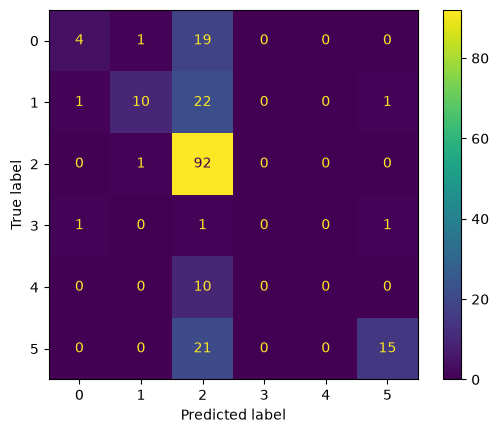

Test prediction: Avalance | ['No Character']
Accuracy: 0.605
F1 Macro: 0.3301108842975031
F1 Weighted: 0.5394277429078354
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.67      0.17      0.27        24
Emotion/Mental State       0.83      0.29      0.43        34
        No Character       0.56      0.99      0.71        93
        Relationship       0.88      0.42      0.57        36

           micro avg       0.60      0.65      0.63       187
           macro avg       0.73      0.47      0.50       187
        weighted avg       0.68      0.65      0.58       187

Character-Related Category | Complement Naive Bayes:


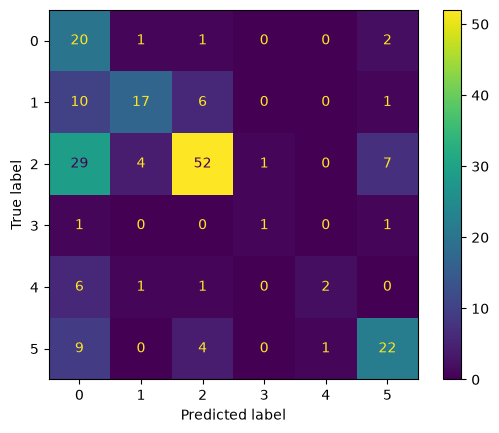

Test prediction: Avalance | ['Biography']
Accuracy: 0.57
F1 Macro: 0.5013875802314637
F1 Weighted: 0.5940810590440523
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.27      0.83      0.40        24
Emotion/Mental State       0.74      0.50      0.60        34
        No Character       0.81      0.56      0.66        93
         Personality       0.50      0.33      0.40         3
    Physical Feature       0.67      0.20      0.31        10
        Relationship       0.67      0.61      0.64        36

            accuracy                           0.57       200
           macro avg       0.61      0.51      0.50       200
        weighted avg       0.70      0.57      0.59       200

Character-Related Category | Linear Support Vector Classification:


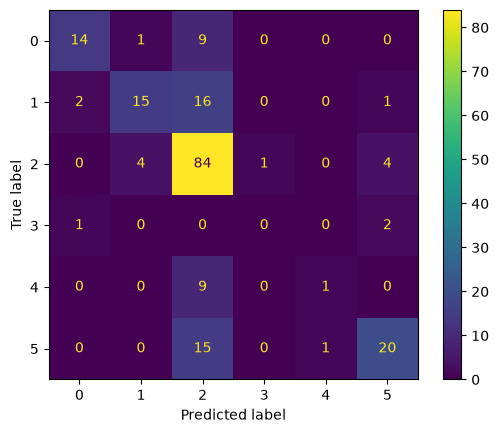

Test prediction: Avalance | ['No Character']
Accuracy: 0.67
F1 Macro: 0.4639054197115928
F1 Weighted: 0.6446784283898466
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.82      0.58      0.68        24
Emotion/Mental State       0.75      0.44      0.56        34
        No Character       0.63      0.90      0.74        93
         Personality       0.00      0.00      0.00         3
    Physical Feature       0.50      0.10      0.17        10
        Relationship       0.74      0.56      0.63        36

            accuracy                           0.67       200
           macro avg       0.57      0.43      0.46       200
        weighted avg       0.68      0.67      0.64       200

Character-Related Category | Logistic Regression:


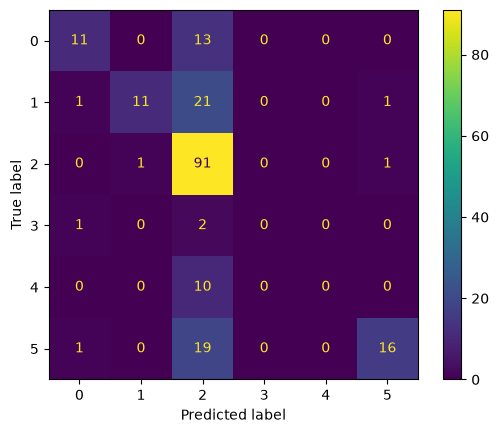

Test prediction: Avalance | ['No Character']
Accuracy: 0.645
F1 Macro: 0.3967874208929965
F1 Weighted: 0.597324216775569
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.79      0.46      0.58        24
Emotion/Mental State       0.92      0.32      0.48        34
        No Character       0.58      0.98      0.73        93
        Relationship       0.89      0.44      0.59        36

           micro avg       0.65      0.69      0.67       187
           macro avg       0.79      0.55      0.60       187
        weighted avg       0.73      0.69      0.64       187

Character-Related Category | K-Nearest Neighbors:


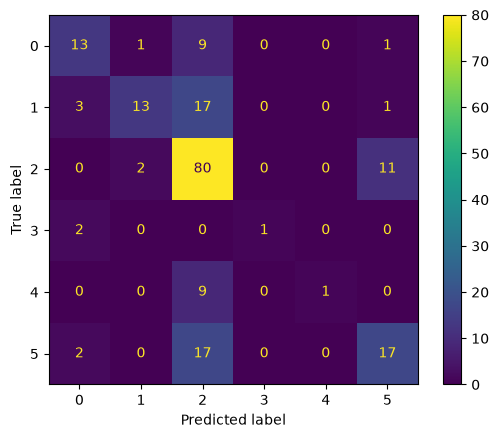

Test prediction: Avalance | ['No Character']
Accuracy: 0.625
F1 Macro: 0.5031649831649831
F1 Weighted: 0.5992939393939394
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.65      0.54      0.59        24
Emotion/Mental State       0.81      0.38      0.52        34
        No Character       0.61      0.86      0.71        93
         Personality       1.00      0.33      0.50         3
    Physical Feature       1.00      0.10      0.18        10
        Relationship       0.57      0.47      0.52        36

            accuracy                           0.62       200
           macro avg       0.77      0.45      0.50       200
        weighted avg       0.66      0.62      0.60       200

Character-Related Category | Support Vector Machines:


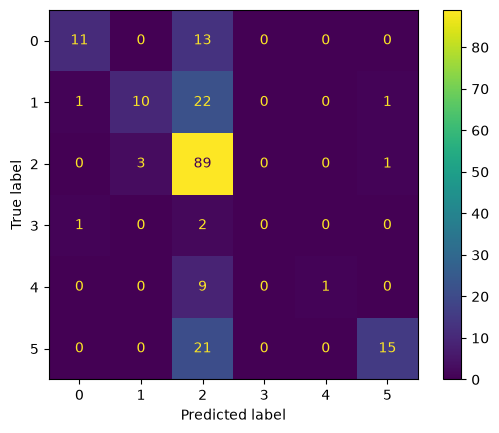

Test prediction: Avalance | ['No Character']
Accuracy: 0.63
F1 Macro: 0.41380697748440903
F1 Weighted: 0.5870791169812224
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.85      0.46      0.59        24
Emotion/Mental State       0.77      0.29      0.43        34
        No Character       0.57      0.96      0.71        93
    Physical Feature       1.00      0.10      0.18        10
        Relationship       0.88      0.42      0.57        36

           micro avg       0.63      0.64      0.63       197
           macro avg       0.81      0.45      0.50       197
        weighted avg       0.72      0.64      0.60       197

Character-Related Category | Decision Trees:


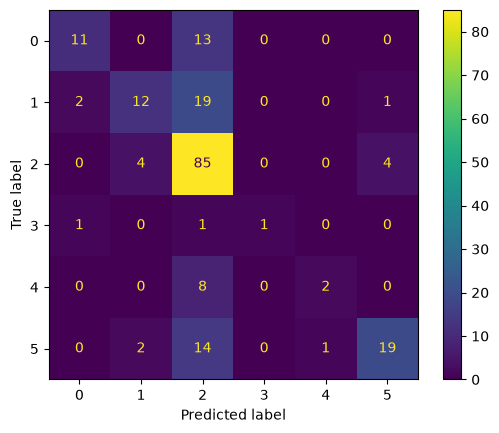

Test prediction: Avalance | ['No Character']
Accuracy: 0.65
F1 Macro: 0.5351875341484559
F1 Weighted: 0.6240902243227745
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.79      0.46      0.58        24
Emotion/Mental State       0.67      0.35      0.46        34
        No Character       0.61      0.91      0.73        93
         Personality       1.00      0.33      0.50         3
    Physical Feature       0.67      0.20      0.31        10
        Relationship       0.79      0.53      0.63        36

            accuracy                           0.65       200
           macro avg       0.75      0.46      0.54       200
        weighted avg       0.68      0.65      0.62       200

Character-Related Category | Random Forest:


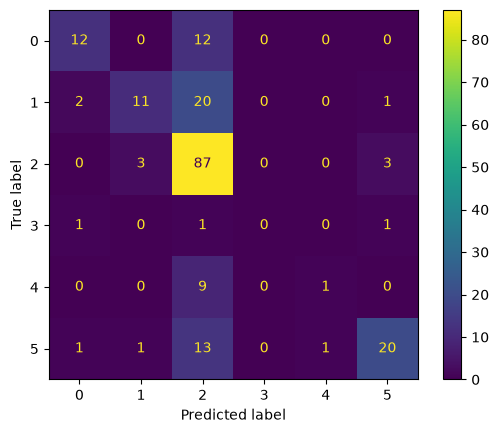

Test prediction: Avalance | ['No Character']
Accuracy: 0.655
F1 Macro: 0.4353015825560546
F1 Weighted: 0.6189905231712497
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.75      0.50      0.60        24
Emotion/Mental State       0.73      0.32      0.45        34
        No Character       0.61      0.94      0.74        93
    Physical Feature       0.50      0.10      0.17        10
        Relationship       0.80      0.56      0.66        36

           micro avg       0.66      0.66      0.66       197
           macro avg       0.68      0.48      0.52       197
        weighted avg       0.68      0.66      0.63       197

Character-Related Category | Gradient Boosting:


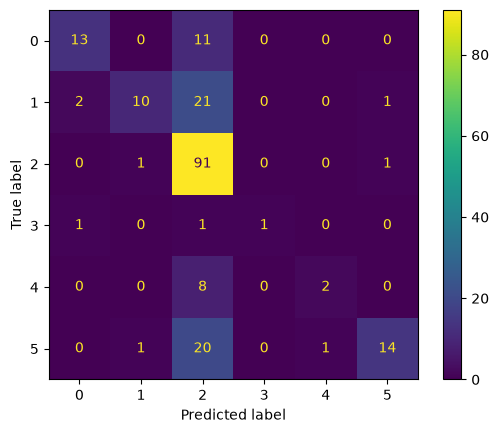

Test prediction: Avalance | ['No Character']
Accuracy: 0.655
F1 Macro: 0.5289655996177736
F1 Weighted: 0.6171493072145247
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.81      0.54      0.65        24
Emotion/Mental State       0.83      0.29      0.43        34
        No Character       0.60      0.98      0.74        93
         Personality       1.00      0.33      0.50         3
    Physical Feature       0.67      0.20      0.31        10
        Relationship       0.88      0.39      0.54        36

            accuracy                           0.66       200
           macro avg       0.80      0.46      0.53       200
        weighted avg       0.72      0.66      0.62       200

Narrative-Related Category | Multinomial Naive Bayes:


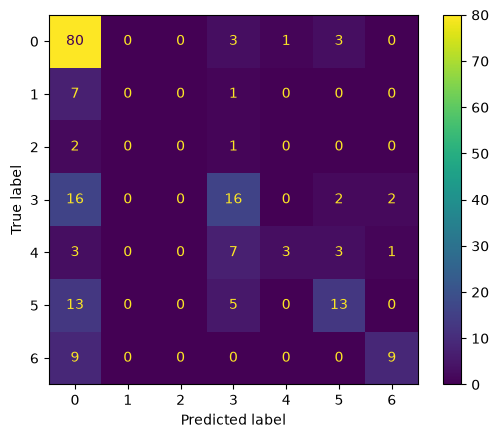

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.605
F1 Macro: 0.36954422722805813
F1 Weighted: 0.5600013023442196
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.62      0.92      0.74        87
        No Narrative       0.48      0.44      0.46        36
                Plot       0.75      0.18      0.29        17
         Theme/Genre       0.62      0.42      0.50        31
        WorldSetting       0.75      0.50      0.60        18

           micro avg       0.60      0.64      0.62       189
           macro avg       0.64      0.49      0.52       189
        weighted avg       0.62      0.64      0.59       189

Narrative-Related Category | Complement Naive Bayes:


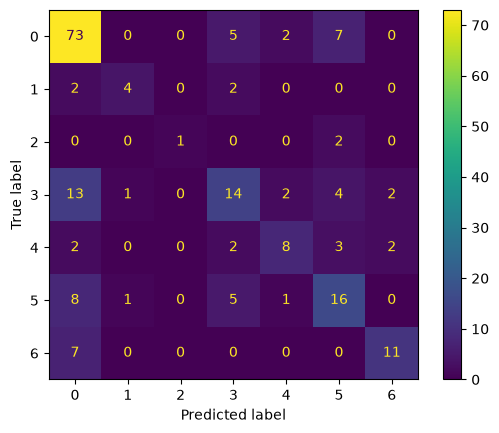

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.635
F1 Macro: 0.5681831065759637
F1 Weighted: 0.6239518849206349
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.70      0.84      0.76        87
              Format       0.67      0.50      0.57         8
   Narrative Methods       1.00      0.33      0.50         3
        No Narrative       0.50      0.39      0.44        36
                Plot       0.62      0.47      0.53        17
         Theme/Genre       0.50      0.52      0.51        31
        WorldSetting       0.73      0.61      0.67        18

            accuracy                           0.64       200
           macro avg       0.67      0.52      0.57       200
        weighted avg       0.63      0.64      0.62       200

Narrative-Related Category | Linear Support Vector Classification:


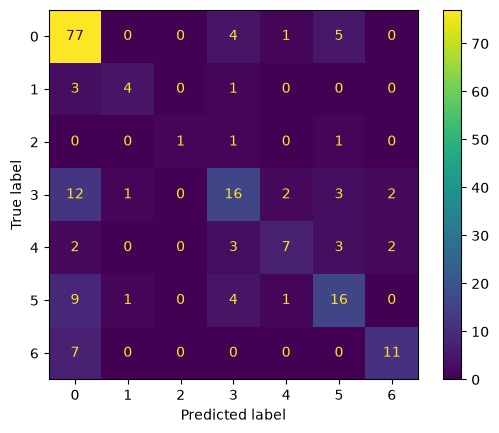

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.66
F1 Macro: 0.5792145285833908
F1 Weighted: 0.6455910855040168
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.70      0.89      0.78        87
              Format       0.67      0.50      0.57         8
   Narrative Methods       1.00      0.33      0.50         3
        No Narrative       0.55      0.44      0.49        36
                Plot       0.64      0.41      0.50        17
         Theme/Genre       0.57      0.52      0.54        31
        WorldSetting       0.73      0.61      0.67        18

            accuracy                           0.66       200
           macro avg       0.69      0.53      0.58       200
        weighted avg       0.65      0.66      0.65       200

Narrative-Related Category | Logistic Regression:


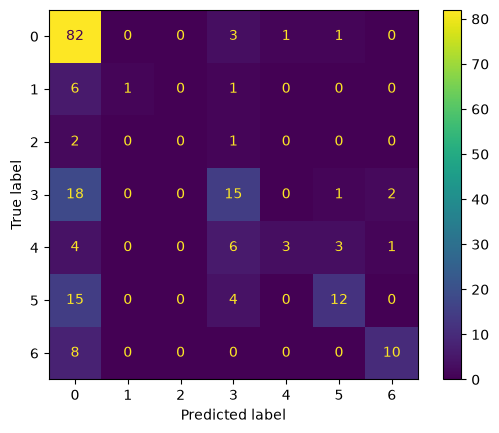

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.615
F1 Macro: 0.40662599879189737
F1 Weighted: 0.5719086524731686
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.61      0.94      0.74        87
              Format       1.00      0.12      0.22         8
        No Narrative       0.50      0.42      0.45        36
                Plot       0.75      0.18      0.29        17
         Theme/Genre       0.71      0.39      0.50        31
        WorldSetting       0.77      0.56      0.65        18

           micro avg       0.61      0.62      0.62       197
           macro avg       0.72      0.43      0.47       197
        weighted avg       0.65      0.62      0.58       197

Narrative-Related Category | K-Nearest Neighbors:


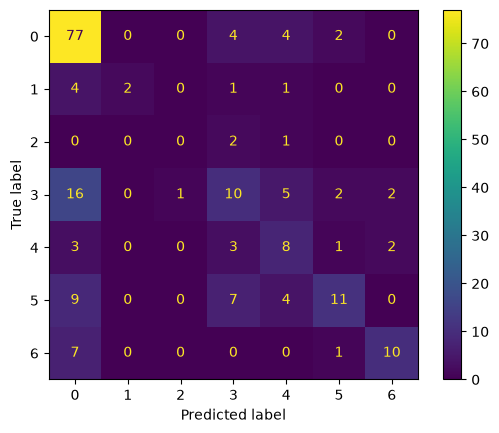

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.59
F1 Macro: 0.4227734772069748
F1 Weighted: 0.5644345238095237
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.66      0.89      0.76        87
              Format       1.00      0.25      0.40         8
   Narrative Methods       0.00      0.00      0.00         3
        No Narrative       0.37      0.28      0.32        36
                Plot       0.35      0.47      0.40        17
         Theme/Genre       0.65      0.35      0.46        31
        WorldSetting       0.71      0.56      0.62        18

            accuracy                           0.59       200
           macro avg       0.53      0.40      0.42       200
        weighted avg       0.59      0.59      0.56       200

Narrative-Related Category | Support Vector Machines:


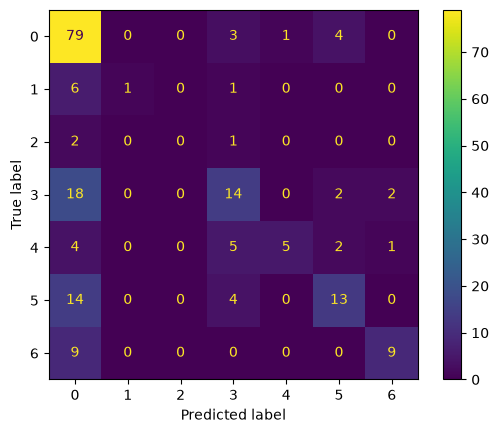

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.605
F1 Macro: 0.4165665740189266
F1 Weighted: 0.5699310270663756
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.60      0.91      0.72        87
              Format       1.00      0.12      0.22         8
        No Narrative       0.50      0.39      0.44        36
                Plot       0.83      0.29      0.43        17
         Theme/Genre       0.62      0.42      0.50        31
        WorldSetting       0.75      0.50      0.60        18

           micro avg       0.60      0.61      0.61       197
           macro avg       0.72      0.44      0.49       197
        weighted avg       0.63      0.61      0.58       197

Narrative-Related Category | Decision Trees:


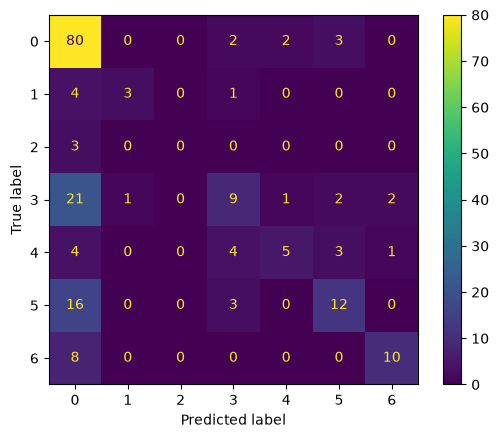

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.595
F1 Macro: 0.43721586316101335
F1 Weighted: 0.556022406827097
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.59      0.92      0.72        87
              Format       0.75      0.38      0.50         8
        No Narrative       0.47      0.25      0.33        36
                Plot       0.62      0.29      0.40        17
         Theme/Genre       0.60      0.39      0.47        31
        WorldSetting       0.77      0.56      0.65        18

           micro avg       0.59      0.60      0.60       197
           macro avg       0.63      0.46      0.51       197
        weighted avg       0.60      0.60      0.56       197

Narrative-Related Category | Random Forest:


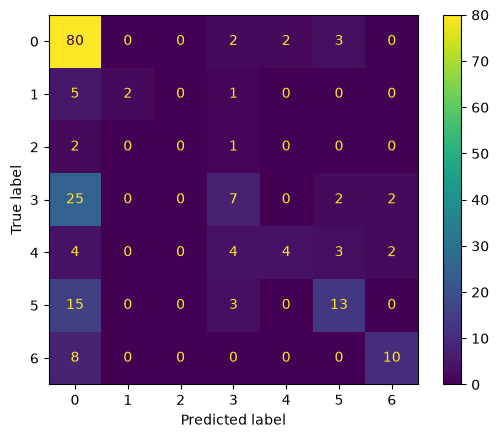

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.58
F1 Macro: 0.4057214211408132
F1 Weighted: 0.5339464858278825
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.58      0.92      0.71        87
              Format       1.00      0.25      0.40         8
        No Narrative       0.39      0.19      0.26        36
                Plot       0.67      0.24      0.35        17
         Theme/Genre       0.62      0.42      0.50        31
        WorldSetting       0.71      0.56      0.62        18

           micro avg       0.58      0.59      0.58       197
           macro avg       0.66      0.43      0.47       197
        weighted avg       0.59      0.59      0.54       197

Narrative-Related Category | Gradient Boosting:


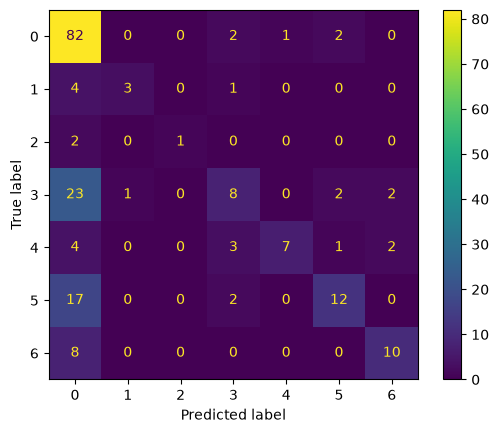

Test prediction: Avalance | ['Event-related/Action']
Accuracy: 0.615
F1 Macro: 0.5307370382921044
F1 Weighted: 0.5785077431379193
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.59      0.94      0.72        87
              Format       0.75      0.38      0.50         8
   Narrative Methods       1.00      0.33      0.50         3
        No Narrative       0.50      0.22      0.31        36
                Plot       0.88      0.41      0.56        17
         Theme/Genre       0.71      0.39      0.50        31
        WorldSetting       0.71      0.56      0.62        18

            accuracy                           0.61       200
           macro avg       0.73      0.46      0.53       200
        weighted avg       0.64      0.61      0.58       200

Content Control Porn | Multinomial Naive Bayes:


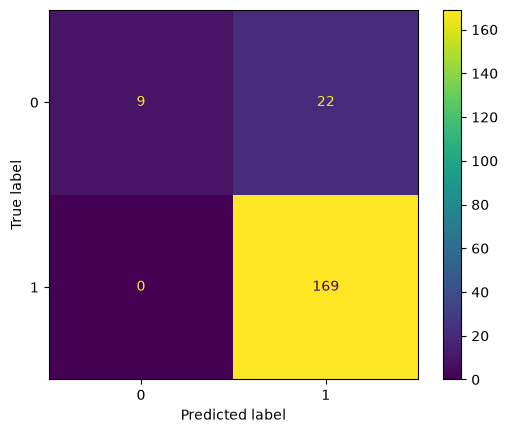

Test prediction: Avalance | ['Not Porn']
Accuracy: 0.89
F1 Macro: 0.6944444444444444
F1 Weighted: 0.863111111111111
Classification Report:
              precision    recall  f1-score   support

     Is Porn       1.00      0.29      0.45        31
    Not Porn       0.88      1.00      0.94       169

    accuracy                           0.89       200
   macro avg       0.94      0.65      0.69       200
weighted avg       0.90      0.89      0.86       200

Content Control Porn | Complement Naive Bayes:


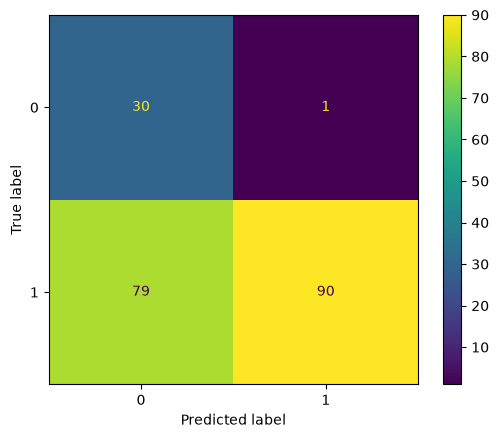

Test prediction: Avalance | ['Is Porn']
Accuracy: 0.6
F1 Macro: 0.5604395604395604
F1 Weighted: 0.6514285714285714
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.28      0.97      0.43        31
    Not Porn       0.99      0.53      0.69       169

    accuracy                           0.60       200
   macro avg       0.63      0.75      0.56       200
weighted avg       0.88      0.60      0.65       200

Content Control Porn | Linear Support Vector Classification:


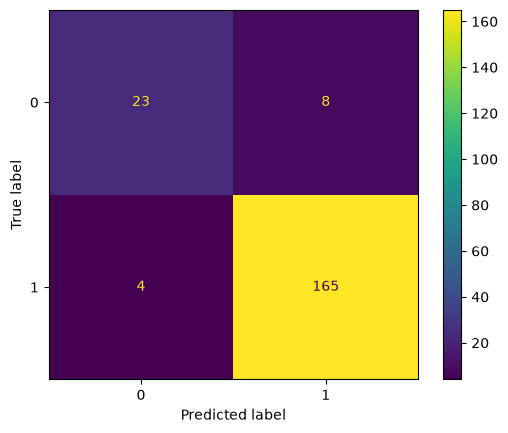

Test prediction: Avalance | ['Not Porn']
Accuracy: 0.94
F1 Macro: 0.8790078644888082
F1 Weighted: 0.938281911675741
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.85      0.74      0.79        31
    Not Porn       0.95      0.98      0.96       169

    accuracy                           0.94       200
   macro avg       0.90      0.86      0.88       200
weighted avg       0.94      0.94      0.94       200

Content Control Porn | Logistic Regression:


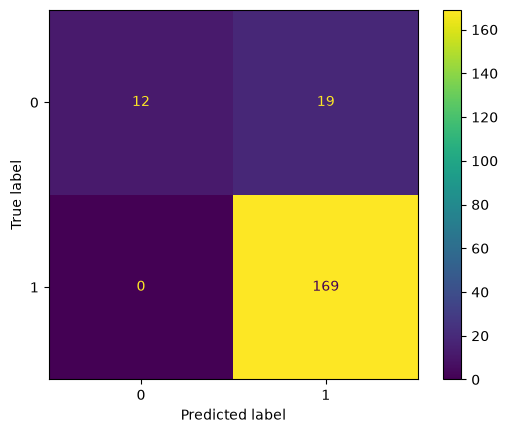

Test prediction: Avalance | ['Not Porn']
Accuracy: 0.905
F1 Macro: 0.7524591231841573
F1 Weighted: 0.8865396391114585
Classification Report:
              precision    recall  f1-score   support

     Is Porn       1.00      0.39      0.56        31
    Not Porn       0.90      1.00      0.95       169

    accuracy                           0.91       200
   macro avg       0.95      0.69      0.75       200
weighted avg       0.91      0.91      0.89       200

Content Control Porn | K-Nearest Neighbors:


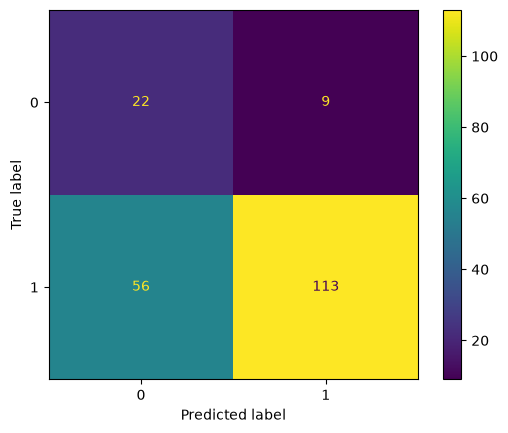

Test prediction: Avalance | ['Is Porn']
Accuracy: 0.675
F1 Macro: 0.5901510135880703
F1 Weighted: 0.7188231028720956
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.28      0.71      0.40        31
    Not Porn       0.93      0.67      0.78       169

    accuracy                           0.68       200
   macro avg       0.60      0.69      0.59       200
weighted avg       0.83      0.68      0.72       200

Content Control Porn | Support Vector Machines:


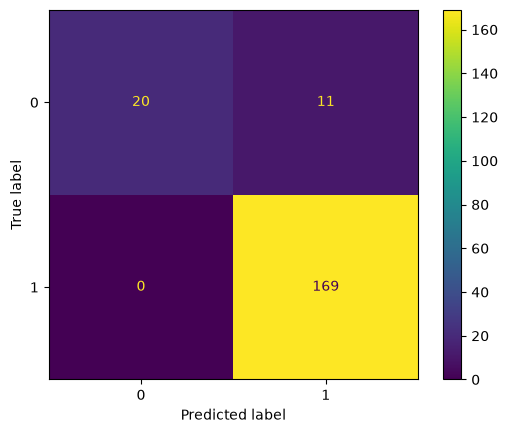

Test prediction: Avalance | ['Not Porn']
Accuracy: 0.945
F1 Macro: 0.8763975504241811
F1 Weighted: 0.9399353896286309
Classification Report:
              precision    recall  f1-score   support

     Is Porn       1.00      0.65      0.78        31
    Not Porn       0.94      1.00      0.97       169

    accuracy                           0.94       200
   macro avg       0.97      0.82      0.88       200
weighted avg       0.95      0.94      0.94       200

Content Control Porn | Decision Trees:


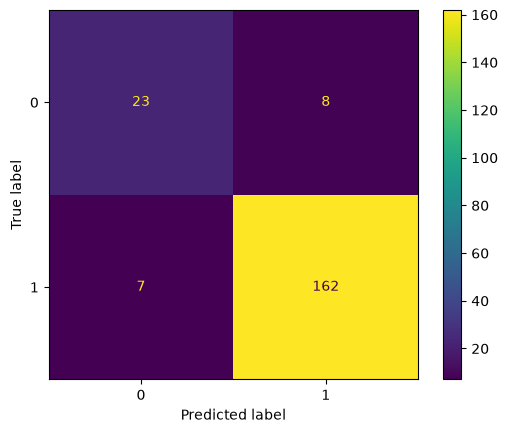

Test prediction: Avalance | ['Not Porn']
Accuracy: 0.925
F1 Macro: 0.8549252865225592
F1 Weighted: 0.924495865370666
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.77      0.74      0.75        31
    Not Porn       0.95      0.96      0.96       169

    accuracy                           0.93       200
   macro avg       0.86      0.85      0.85       200
weighted avg       0.92      0.93      0.92       200

Content Control Porn | Random Forest:


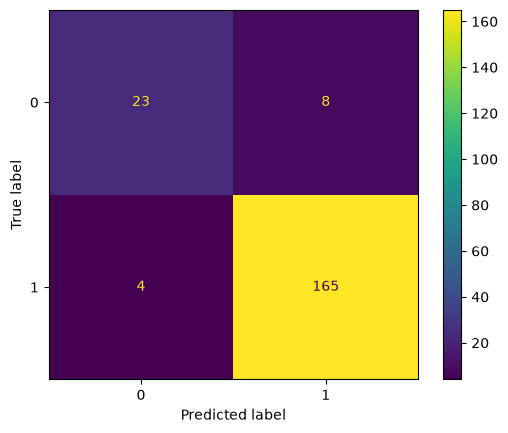

Test prediction: Avalance | ['Not Porn']
Accuracy: 0.94
F1 Macro: 0.8790078644888082
F1 Weighted: 0.938281911675741
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.85      0.74      0.79        31
    Not Porn       0.95      0.98      0.96       169

    accuracy                           0.94       200
   macro avg       0.90      0.86      0.88       200
weighted avg       0.94      0.94      0.94       200

Content Control Porn | Gradient Boosting:


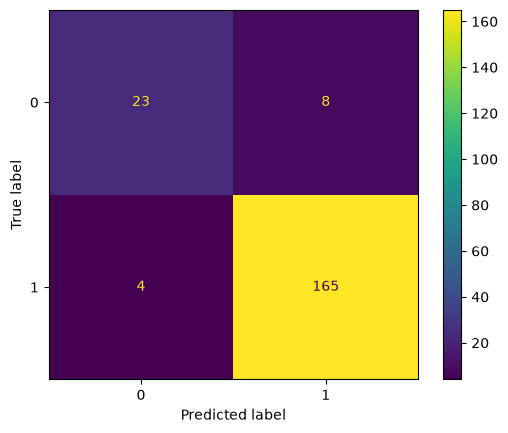

Test prediction: Avalance | ['Not Porn']
Accuracy: 0.94
F1 Macro: 0.8790078644888082
F1 Weighted: 0.938281911675741
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.85      0.74      0.79        31
    Not Porn       0.95      0.98      0.96       169

    accuracy                           0.94       200
   macro avg       0.90      0.86      0.88       200
weighted avg       0.94      0.94      0.94       200

Content Control Kink | Multinomial Naive Bayes:


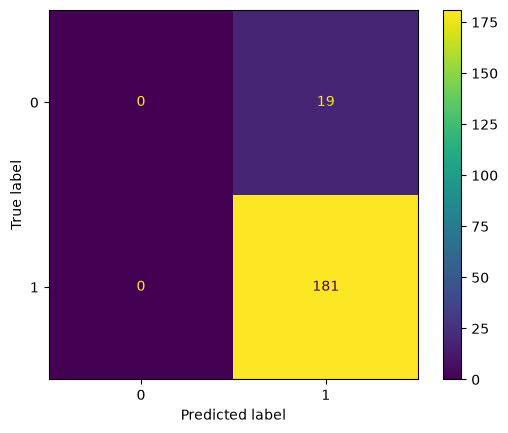

Test prediction: Avalance | ['Not Kink']
Accuracy: 0.905
F1 Macro: 0.47506561679790027
F1 Weighted: 0.8598687664041995
Classification Report:
              precision    recall  f1-score   support

    Not Kink       0.91      1.00      0.95       181

   micro avg       0.91      1.00      0.95       181
   macro avg       0.91      1.00      0.95       181
weighted avg       0.91      1.00      0.95       181

Content Control Kink | Complement Naive Bayes:


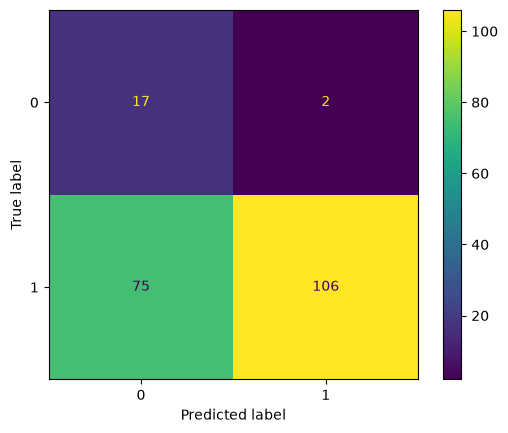

Test prediction: Avalance | ['Is Kink']
Accuracy: 0.615
F1 Macro: 0.5199351600735684
F1 Weighted: 0.6929745316250506
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.18      0.89      0.31        19
    Not Kink       0.98      0.59      0.73       181

    accuracy                           0.61       200
   macro avg       0.58      0.74      0.52       200
weighted avg       0.91      0.61      0.69       200

Content Control Kink | Linear Support Vector Classification:


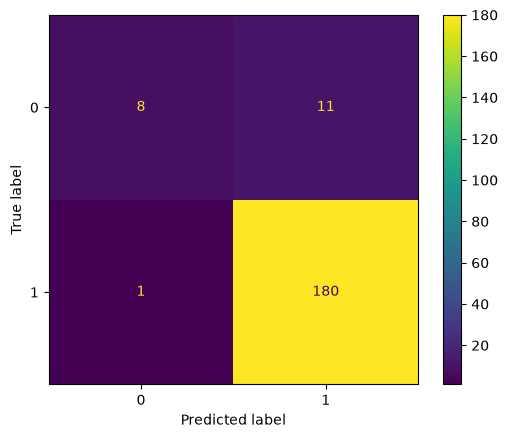

Test prediction: Avalance | ['Not Kink']
Accuracy: 0.94
F1 Macro: 0.7695852534562212
F1 Weighted: 0.9300921658986175
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.89      0.42      0.57        19
    Not Kink       0.94      0.99      0.97       181

    accuracy                           0.94       200
   macro avg       0.92      0.71      0.77       200
weighted avg       0.94      0.94      0.93       200

Content Control Kink | Logistic Regression:


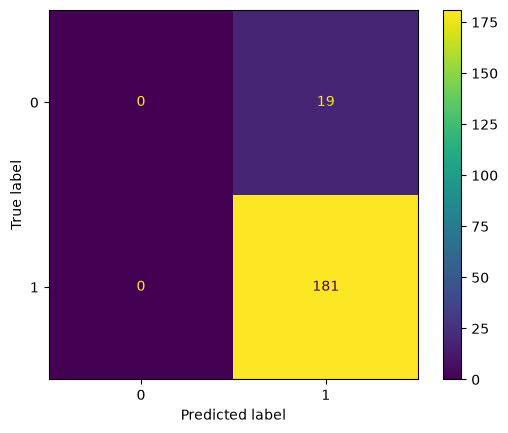

Test prediction: Avalance | ['Not Kink']
Accuracy: 0.905
F1 Macro: 0.47506561679790027
F1 Weighted: 0.8598687664041995
Classification Report:
              precision    recall  f1-score   support

    Not Kink       0.91      1.00      0.95       181

   micro avg       0.91      1.00      0.95       181
   macro avg       0.91      1.00      0.95       181
weighted avg       0.91      1.00      0.95       181

Content Control Kink | K-Nearest Neighbors:


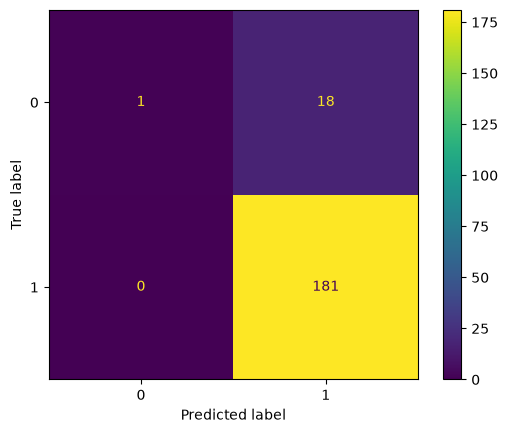

Test prediction: Avalance | ['Not Kink']
Accuracy: 0.91
F1 Macro: 0.5263157894736842
F1 Weighted: 0.8716315789473684
Classification Report:
              precision    recall  f1-score   support

     Is Kink       1.00      0.05      0.10        19
    Not Kink       0.91      1.00      0.95       181

    accuracy                           0.91       200
   macro avg       0.95      0.53      0.53       200
weighted avg       0.92      0.91      0.87       200

Content Control Kink | Support Vector Machines:


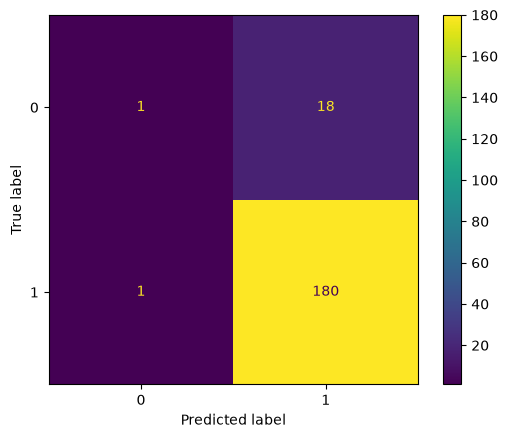

Test prediction: Avalance | ['Not Kink']
Accuracy: 0.905
F1 Macro: 0.5225530845583616
F1 Weighted: 0.8686782259077772
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.50      0.05      0.10        19
    Not Kink       0.91      0.99      0.95       181

    accuracy                           0.91       200
   macro avg       0.70      0.52      0.52       200
weighted avg       0.87      0.91      0.87       200

Content Control Kink | Decision Trees:


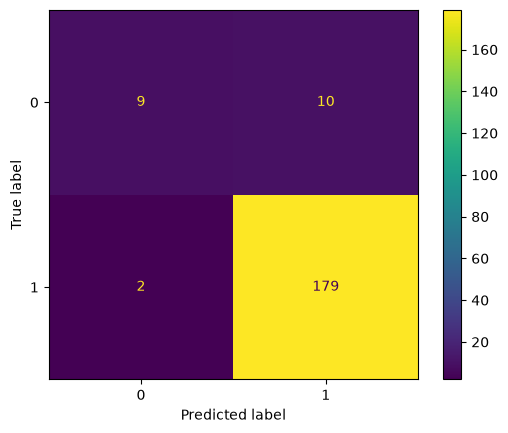

Test prediction: Avalance | ['Not Kink']
Accuracy: 0.94
F1 Macro: 0.7837837837837838
F1 Weighted: 0.9326486486486486
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.82      0.47      0.60        19
    Not Kink       0.95      0.99      0.97       181

    accuracy                           0.94       200
   macro avg       0.88      0.73      0.78       200
weighted avg       0.93      0.94      0.93       200

Content Control Kink | Random Forest:


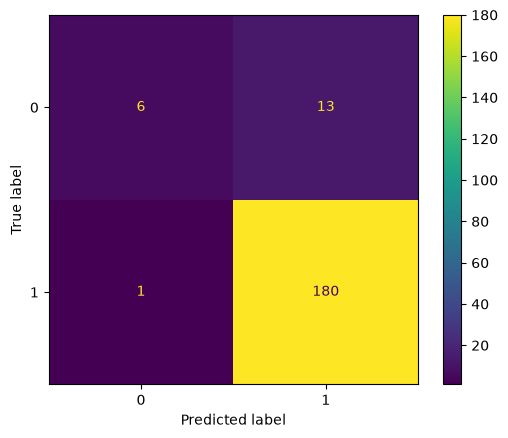

Test prediction: Avalance | ['Not Kink']
Accuracy: 0.93
F1 Macro: 0.7120526532291238
F1 Weighted: 0.9149691484985603
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.86      0.32      0.46        19
    Not Kink       0.93      0.99      0.96       181

    accuracy                           0.93       200
   macro avg       0.89      0.66      0.71       200
weighted avg       0.93      0.93      0.91       200

Content Control Kink | Gradient Boosting:


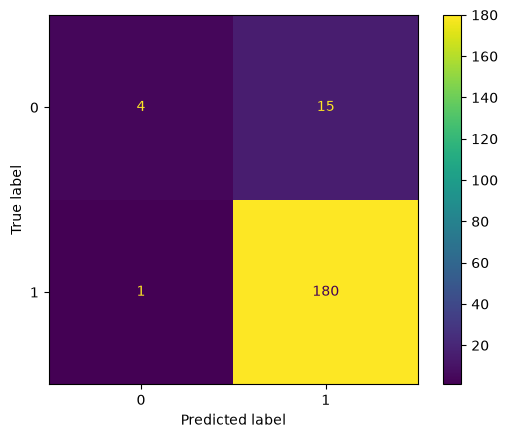

Test prediction: Avalance | ['Not Kink']
Accuracy: 0.92
F1 Macro: 0.6453900709219859
F1 Weighted: 0.8981560283687944
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.80      0.21      0.33        19
    Not Kink       0.92      0.99      0.96       181

    accuracy                           0.92       200
   macro avg       0.86      0.60      0.65       200
weighted avg       0.91      0.92      0.90       200



Classification,Classifier,Accuracy,Precision Macro,Precision Weighted,Recall Macro,Recall Weighted,F1 Macro,F1 Weighted,Test Tag,Test Prediction
str,str,f64,f64,f64,f64,f64,f64,f64,str,str
"""Character-Related Category""","""Multinomial Naive Bayes""",0.605,0.489988,0.639763,0.311116,0.605,0.330111,0.539428,"""Avalance""","""No Character"""
"""Character-Related Category""","""Complement Naive Bayes""",0.57,0.608605,0.696298,0.506153,0.57,0.501388,0.594081,"""Avalance""","""Biography"""
"""Character-Related Category""","""Linear Support Vector Classifi…",0.67,0.574308,0.678341,0.430549,0.67,0.463905,0.644678,"""Avalance""","""No Character"""
"""Character-Related Category""","""Logistic Regression""",0.645,0.529101,0.681369,0.367467,0.645,0.396787,0.597324,"""Avalance""","""No Character"""
"""Character-Related Category""","""K-Nearest Neighbors""",0.625,0.772538,0.664943,0.448298,0.625,0.503165,0.599294,"""Avalance""","""No Character"""
"""Character-Related Category""","""Support Vector Machines""",0.63,0.678042,0.70642,0.371018,0.63,0.413807,0.587079,"""Avalance""","""No Character"""
"""Character-Related Category""","""Decision Trees""",0.65,0.752976,0.680774,0.464394,0.65,0.535188,0.62409,"""Avalance""","""No Character"""
"""Character-Related Category""","""Random Forest""",0.655,0.566002,0.668561,0.402428,0.655,0.435302,0.618991,"""Avalance""","""No Character"""
"""Character-Related Category""","""Gradient Boosting""",0.655,0.797697,0.723388,0.456084,0.655,0.528966,0.617149,"""Avalance""","""No Character"""


In [7]:
classifiers = [MultinomialNB(), ComplementNB(), LinearSVC(), LogisticRegression(), KNeighborsClassifier(), SVC(), DecisionTreeClassifier(), RandomForestClassifier(), GradientBoostingClassifier()]
classifier_names = ['Multinomial Naive Bayes', 'Complement Naive Bayes', 'Linear Support Vector Classification', 'Logistic Regression', 'K-Nearest Neighbors', 'Support Vector Machines', 'Decision Trees', 'Random Forest', 'Gradient Boosting']
classification = ['Character-Related Category', 'Narrative-Related Category', 'Content Control Porn', 'Content Control Kink']

df_stats = pl.DataFrame()
i = 0
for y_value in y_values:
    for j in range(len(classifiers)):
        df_stats = pl.concat([df_stats, compare_classifiers(y_value, classifiers[j], classifier_names[j], classification[i], "Avalance")])
    i += 1

df_stats.show(36)

## 3. Comparing the Classification Models

### 3.1 Creating the Comparison Tables

In [8]:
def table():
    """
    Creates a DataFrame.

    Returns:
        Polars DataFrame: Consists of a filtered table.
    """
    return pl.DataFrame({
        "Classifier": "",
        "Character-Related Category": "",
        "Narrative-Related Category": "",
        "Content Control Porn": "",
        "Content Control Kink": ""
    })

In [9]:
def change_table(df, classifier_index, classifier_name):
    """
    Cleans the DataFrame.

    Parameter:
        df (DataFrame): To filter
        classifier_index (integer): Index of the classifier in the classifier_names list.
        classifier_name (string): Name of the classifier.
    Returns:
        df_temp (DataFrame): Consists of a filtered table.
    """
    # Turn DataFrame horizontally
    df_temp = df.filter(pl.col("Classifier") == classifier_names[classifier_index]).transpose(column_names=["Character-Related Category", "Narrative-Related Category", "Content Control Porn", "Content Control Kink"]).with_row_index()
    # Create the Classifier column
    c = pl.Series("Classifier", [classifier_name] * 3)
    # Add the Classifier column and remove the index column
    df_temp = df_temp.insert_column(1, c).remove(pl.col("index") < 2).drop("index")

    return df_temp

In [10]:
def remove_empty_row(table):
    """
    Removes the Classifier column.

    Returns:
        Polars DataFrame: Consists of a filtered table.
    """
    return table.remove(pl.col("Classifier") == "")

In [11]:
df_stats_clone = df_stats.clone()
df_accuracy_classification = df_stats_clone.drop(["Precision Macro", "Precision Weighted", "Recall Macro", "Recall Weighted", "F1 Macro", "F1 Weighted", "Test Tag", "Test Prediction"])
df_precision_macro_classification = df_stats_clone.drop(["Accuracy", "Precision Weighted", "Recall Macro", "Recall Weighted", "F1 Macro", "F1 Weighted", "Test Tag", "Test Prediction"])
df_precision_weighted_classification = df_stats_clone.drop(["Accuracy", "Precision Macro", "Recall Macro", "Recall Weighted", "F1 Macro", "F1 Weighted", "Test Tag", "Test Prediction"])
df_recall_macro_classification = df_stats_clone.drop(["Accuracy", "Precision Macro", "Precision Weighted", "Recall Weighted", "F1 Macro", "F1 Weighted", "Test Tag", "Test Prediction"])
df_recall_weighted_classification = df_stats_clone.drop(["Accuracy", "Precision Macro", "Precision Weighted", "Recall Macro", "F1 Macro", "F1 Weighted", "Test Tag", "Test Prediction"])
df_f1_macro_classification = df_stats_clone.drop(["Accuracy", "Precision Macro", "Precision Weighted", "Recall Macro", "Recall Weighted", "F1 Weighted", "Test Tag", "Test Prediction"])
df_f1_weighted_classification = df_stats_clone.drop(["Accuracy", "Precision Macro", "Precision Weighted", "Recall Macro", "Recall Weighted", "F1 Macro", "Test Tag", "Test Prediction"])
df_test_tag_classification = df_stats_clone.drop(["Accuracy", "Precision Macro", "Precision Weighted", "Recall Macro", "Recall Weighted", "F1 Macro", "F1 Weighted", "Test Tag"])

df_accuracy = table()
df_precision_macro = table()
df_precision_weighted = table()
df_recall_macro = table()
df_recall_weighted = table()
df_f1_macro = table()
df_f1_weighted = table()
df_test_tag = table()
classifier_index = 0
for classifier_name in classifier_names:
    df_accuracy.extend(change_table(df_accuracy_classification, classifier_index, classifier_name))
    df_precision_macro.extend(change_table(df_precision_macro_classification, classifier_index, classifier_name))
    df_precision_weighted.extend(change_table(df_precision_weighted_classification, classifier_index, classifier_name))
    df_recall_macro.extend(change_table(df_recall_macro_classification, classifier_index, classifier_name))
    df_recall_weighted.extend(change_table(df_recall_weighted_classification, classifier_index, classifier_name))
    df_f1_macro.extend(change_table(df_f1_macro_classification, classifier_index, classifier_name))
    df_f1_weighted.extend(change_table(df_f1_weighted_classification, classifier_index, classifier_name))
    df_test_tag.extend(change_table(df_test_tag_classification, classifier_index, classifier_name))
    classifier_index += 1

# Remove empty row
df_accuracy = remove_empty_row(df_accuracy)
df_precision_macro = remove_empty_row(df_precision_macro)
df_precision_weighted = remove_empty_row(df_precision_weighted)
df_recall_macro = remove_empty_row(df_recall_macro)
df_recall_weighted = remove_empty_row(df_recall_weighted)
df_f1_macro = remove_empty_row(df_f1_macro)
df_f1_weighted = remove_empty_row(df_f1_weighted)
df_test_tag = remove_empty_row(df_test_tag)

### 3.2 Accuracy Score

In [12]:
print("Accuracy:")
df_accuracy

Accuracy:


Classifier,Character-Related Category,Narrative-Related Category,Content Control Porn,Content Control Kink
str,str,str,str,str
"""Multinomial Naive Bayes""","""0.605""","""0.605""","""0.89""","""0.905"""
"""Complement Naive Bayes""","""0.57""","""0.635""","""0.6""","""0.615"""
"""Linear Support Vector Classifi…","""0.67""","""0.66""","""0.94""","""0.94"""
"""Logistic Regression""","""0.645""","""0.615""","""0.905""","""0.905"""
"""K-Nearest Neighbors""","""0.625""","""0.59""","""0.675""","""0.91"""
"""Support Vector Machines""","""0.63""","""0.605""","""0.945""","""0.905"""
"""Decision Trees""","""0.65""","""0.595""","""0.925""","""0.94"""
"""Random Forest""","""0.655""","""0.58""","""0.94""","""0.93"""
"""Gradient Boosting""","""0.655""","""0.615""","""0.94""","""0.92"""


### 3.3 Precision Scores

In [13]:
print("Precision Macro:")
df_precision_macro

Precision Macro:


Classifier,Character-Related Category,Narrative-Related Category,Content Control Porn,Content Control Kink
str,str,str,str,str
"""Multinomial Naive Bayes""","""0.4899881164587047""","""0.45989724561153134""","""0.9424083769633508""","""0.4525"""
"""Complement Naive Bayes""","""0.608605072463768""","""0.6729461015175301""","""0.6321201734045772""","""0.5831320450885669"""
"""Linear Support Vector Classifi…","""0.5743081833123113""","""0.694216620817606""","""0.902804538642689""","""0.9156486329261198"""
"""Logistic Regression""","""0.5291005291005291""","""0.6189315042256219""","""0.949468085106383""","""0.4525"""
"""K-Nearest Neighbors""","""0.7725378787878787""","""0.5347620140843277""","""0.6041403951240016""","""0.9547738693467337"""
"""Support Vector Machines""","""0.6780417295123179""","""0.6144094001236858""","""0.9694444444444444""","""0.7045454545454546"""
"""Decision Trees""","""0.7529761904761904""","""0.543735753410676""","""0.8598039215686275""","""0.8826358826358827"""
"""Random Forest""","""0.5660015649452269""","""0.5663469224620303""","""0.902804538642689""","""0.8948926720947445"""
"""Gradient Boosting""","""0.7976973684210527""","""0.7329831932773109""","""0.902804538642689""","""0.8615384615384616"""


In [14]:
print("Precision Weighted:")
df_precision_weighted

Precision Weighted:


Classifier,Character-Related Category,Narrative-Related Category,Content Control Porn,Content Control Kink
str,str,str,str,str
"""Multinomial Naive Bayes""","""0.6397629233511587""","""0.5821674159174158""","""0.9026701570680628""","""0.819025"""
"""Complement Naive Bayes""","""0.6962980072463768""","""0.6299029304029304""","""0.8783748361730013""","""0.9057950885668278"""
"""Linear Support Vector Classifi…","""0.6783410732714138""","""0.6541393491565904""","""0.9379618925283666""","""0.9373240255962769"""
"""Logistic Regression""","""0.6813690476190476""","""0.6366147561588736""","""0.9146010638297872""","""0.819025"""
"""K-Nearest Neighbors""","""0.6649431818181819""","""0.5895617159907441""","""0.8263818831441783""","""0.918140703517588"""
"""Support Vector Machines""","""0.7064196832579185""","""0.6246266233766233""","""0.9483611111111111""","""0.8702272727272726"""
"""Decision Trees""","""0.6807738095238095""","""0.5865012800666826""","""0.9240686274509804""","""0.9348436748436748"""
"""Random Forest""","""0.6685610328638498""","""0.5772644741349777""","""0.9379618925283666""","""0.9254700222057735"""
"""Gradient Boosting""","""0.723388157894737""","""0.6378581932773109""","""0.9379618925283666""","""0.9113846153846155"""


### 3.4 Recall Scores

In [15]:
print("Recall Macro:")
df_recall_macro

Recall Macro:


Classifier,Character-Related Category,Narrative-Related Category,Content Control Porn,Content Control Kink
str,str,str,str,str
"""Multinomial Naive Bayes""","""0.3111163820366857""","""0.35140144303921045""","""0.6451612903225806""","""0.5"""
"""Complement Naive Bayes""","""0.5061529271206692""","""0.5227330086650901""","""0.750143157091048""","""0.7401861006106426"""
"""Linear Support Vector Classifi…","""0.43054852765478957""","""0.5288342997562391""","""0.8591334224088567""","""0.7077638848502472"""
"""Logistic Regression""","""0.36746696886639957""","""0.37190261718332124""","""0.6935483870967742""","""0.5"""
"""K-Nearest Neighbors""","""0.44829836952702234""","""0.3991168213670341""","""0.6891582363046382""","""0.5263157894736842"""
"""Support Vector Machines""","""0.3710178157284419""","""0.37648676452412627""","""0.8225806451612903""","""0.5235533585344577"""
"""Decision Trees""","""0.46439401925644813""","""0.3973300295275693""","""0.8502576827638862""","""0.7313172433847048"""
"""Random Forest""","""0.40242813971466723""","""0.3677413123202563""","""0.8591334224088567""","""0.6551323059028787"""
"""Gradient Boosting""","""0.4560835266006044""","""0.46107161811702796""","""0.8591334224088567""","""0.6025007269555103"""


In [16]:
print("Recall Weighted:")
df_recall_weighted

Recall Weighted:


Classifier,Character-Related Category,Narrative-Related Category,Content Control Porn,Content Control Kink
str,str,str,str,str
"""Multinomial Naive Bayes""","""0.605""","""0.605""","""0.89""","""0.905"""
"""Complement Naive Bayes""","""0.57""","""0.635""","""0.6000000000000001""","""0.6149999999999999"""
"""Linear Support Vector Classifi…","""0.67""","""0.66""","""0.94""","""0.94"""
"""Logistic Regression""","""0.645""","""0.615""","""0.905""","""0.905"""
"""K-Nearest Neighbors""","""0.625""","""0.59""","""0.675""","""0.91"""
"""Support Vector Machines""","""0.63""","""0.605""","""0.945""","""0.905"""
"""Decision Trees""","""0.65""","""0.595""","""0.925""","""0.94"""
"""Random Forest""","""0.655""","""0.58""","""0.94""","""0.93"""
"""Gradient Boosting""","""0.655""","""0.615""","""0.94""","""0.92"""


### 3.5 F1 Scores

In [17]:
print("F1 Macro:")
df_f1_macro

F1 Macro:


Classifier,Character-Related Category,Narrative-Related Category,Content Control Porn,Content Control Kink
str,str,str,str,str
"""Multinomial Naive Bayes""","""0.3301108842975031""","""0.36954422722805813""","""0.6944444444444444""","""0.47506561679790027"""
"""Complement Naive Bayes""","""0.5013875802314637""","""0.5681831065759637""","""0.5604395604395604""","""0.5199351600735684"""
"""Linear Support Vector Classifi…","""0.4639054197115928""","""0.5792145285833908""","""0.8790078644888082""","""0.7695852534562212"""
"""Logistic Regression""","""0.3967874208929965""","""0.40662599879189737""","""0.7524591231841573""","""0.47506561679790027"""
"""K-Nearest Neighbors""","""0.5031649831649831""","""0.4227734772069748""","""0.5901510135880703""","""0.5263157894736842"""
"""Support Vector Machines""","""0.41380697748440903""","""0.4165665740189266""","""0.8763975504241811""","""0.5225530845583616"""
"""Decision Trees""","""0.5351875341484559""","""0.43721586316101335""","""0.8549252865225592""","""0.7837837837837838"""
"""Random Forest""","""0.4353015825560546""","""0.4057214211408132""","""0.8790078644888082""","""0.7120526532291238"""
"""Gradient Boosting""","""0.5289655996177736""","""0.5307370382921044""","""0.8790078644888082""","""0.6453900709219859"""


In [18]:
print("F1 Weighted:")
df_f1_weighted

F1 Weighted:


Classifier,Character-Related Category,Narrative-Related Category,Content Control Porn,Content Control Kink
str,str,str,str,str
"""Multinomial Naive Bayes""","""0.5394277429078354""","""0.5600013023442196""","""0.863111111111111""","""0.8598687664041995"""
"""Complement Naive Bayes""","""0.5940810590440523""","""0.6239518849206349""","""0.6514285714285714""","""0.6929745316250506"""
"""Linear Support Vector Classifi…","""0.6446784283898466""","""0.6455910855040168""","""0.938281911675741""","""0.9300921658986175"""
"""Logistic Regression""","""0.597324216775569""","""0.5719086524731686""","""0.8865396391114585""","""0.8598687664041995"""
"""K-Nearest Neighbors""","""0.5992939393939394""","""0.5644345238095237""","""0.7188231028720956""","""0.8716315789473684"""
"""Support Vector Machines""","""0.5870791169812224""","""0.5699310270663756""","""0.9399353896286309""","""0.8686782259077772"""
"""Decision Trees""","""0.6240902243227745""","""0.556022406827097""","""0.924495865370666""","""0.9326486486486486"""
"""Random Forest""","""0.6189905231712497""","""0.5339464858278825""","""0.938281911675741""","""0.9149691484985603"""
"""Gradient Boosting""","""0.6171493072145247""","""0.5785077431379193""","""0.938281911675741""","""0.8981560283687944"""


### 3.6 Test Tag

In [19]:
print("Test Tag:")
df_test_tag

Test Tag:


Classifier,Character-Related Category,Narrative-Related Category,Content Control Porn,Content Control Kink
str,str,str,str,str
"""Multinomial Naive Bayes""","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
"""Complement Naive Bayes""","""Biography""","""Event-related/Action""","""Is Porn""","""Is Kink"""
"""Linear Support Vector Classifi…","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
"""Logistic Regression""","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
"""K-Nearest Neighbors""","""No Character""","""Event-related/Action""","""Is Porn""","""Not Kink"""
"""Support Vector Machines""","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
"""Decision Trees""","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
"""Random Forest""","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
"""Gradient Boosting""","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
